In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.ticker as plticke



In [4]:
#Chargement des données propres
df = pd.read_csv('../dataset/traite/train_cleaned.csv')

In [19]:
# Vérification des types de données de chaque colonne
df.dtypes

Order                       int64
MS SubClass                 int64
Lot Frontage              float64
Lot Area                    int64
Street                      int64
Alley                       int64
Lot Shape                   int64
Land Slope                  int64
Overall Qual                int64
Overall Cond                int64
Year Built                  int64
Year Remod/Add              int64
Mas Vnr Area              float64
Exter Qual                  int64
Exter Cond                  int64
Bsmt Qual                   int64
Bsmt Cond                   int64
Bsmt Exposure               int64
BsmtFin Type 1              int64
BsmtFin SF 1              float64
BsmtFin Type 2              int64
BsmtFin SF 2              float64
Bsmt Unf SF               float64
Total Bsmt SF             float64
Heating QC                  int64
Central Air                 int64
1st Flr SF                  int64
2nd Flr SF                  int64
Low Qual Fin SF             int64
Gr Liv Area   

Les données du dataset sont majoritairement composées de variables numériques de type int64 et float64, représentant des caractéristiques quantitatives des biens immobiliers. On observe également la présence de variables booléennes (bool), issues de l’encodage des variables catégorielles (One-Hot Encoding).

Cette structure rend le dataset directement exploitable par les modèles de régression linéaire avec régularisation (Ridge), Random Forest et XGBoost, qui nécessitent des entrées numériques. Les variables booléennes sont automatiquement interprétées comme des valeurs binaires (0/1), ce qui est compatible avec ces algorithmes.

Ainsi, aucune transformation supplémentaire des types de données n’est requise avant l’entraînement des modèles, ce qui permet de se concentrer sur l’évaluation et l’optimisation des performances prédictives.

Dans cette étape, nous séparons la variable cible SalePrice, qui correspond au prix de vente que nous souhaitons prédire, des variables explicatives X qui représentent les caractéristiques descriptives des biens immobiliers. Cette séparation est essentielle car les modèles de machine learning tels que: "la régression Ridge, le Random Forest et XGBoost" apprennent à partir des caractéristiques d’entrée (X) pour estimer la variable cible (y).

Cela permet d’entraîner les modèles en leur fournissant clairement les données d’entrée et la sortie attendue, facilitant ainsi la construction d’un modèle capable de faire des prédictions précises sur de nouvelles données.

In [5]:
# Séparation Features (X) / Target (y)
y = df['SalePrice']
X = df.drop('SalePrice', axis=1)

Afin d’évaluer la performance réelle de nos modèles prédictifs, nous utilisons une technique appelée validation croisée par K-fold. Cette méthode consiste à diviser le jeu de données en plusieurs sous-ensembles (ici 5 folds), puis à entraîner le modèle sur 4 folds tout en testant ses performances sur le fold restant. Ce processus est répété pour chaque fold, ce qui permet d’obtenir une estimation plus fiable et robuste de la performance du modèle, en limitant les risques de sur-apprentissage (overfitting) ou de biais liés à un découpage particulier des données.

Pour éviter que l’ordre initial des données n’influence la division, nous mélangeons les observations avant de les répartir. De plus, en fixant une graine aléatoire, nous garantissons la reproductibilité des résultats.

Comme métrique d’évaluation, nous utilisons la racine de l’erreur quadratique moyenne (RMSE), qui mesure en moyenne la distance entre les prédictions et les valeurs réelles. Une RMSE faible indique un bon ajustement du modèle aux données. Cette métrique est particulièrement adaptée aux problèmes de régression comme la prédiction du prix de vente immobilier.



In [6]:
# Définition de la méthode de validation (Cross-Validation)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Fonction pour calculer la RMSE moyenne en validation croisée
# cross_val_score effectue l'entraînement et la validation du modèle sur chaque fold
# scoring="neg_mean_squared_error" utilise l'erreur quadratique moyenne négative (pour sklearn, le score doit être maximisé)
# on applique np.sqrt et on inverse le signe pour obtenir la RMSE (Root Mean Squared Error)
# La RMSE mesure l'écart moyen entre les prédictions du modèle et les valeurs réelles
# Plus la RMSE est faible, meilleure est la qualité prédictive du modèle

def cv_rmse(model):
    rmse = np.sqrt(-cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=kf))
    return rmse

In [7]:
# Modèle 1

#A)Régression Linéaire Multiple Standard (Sans filet de sécurité)
lr_model = LinearRegression()

score_lr = cv_rmse(lr_model)
print(f"Linear Regression (OLS) Score: {score_lr.mean():.4f} (std: {score_lr.std():.4f})")


Linear Regression (OLS) Score: 0.1243 (std: 0.0167)


In [8]:
# Modèle 1 

#B) Régression Linéaire (Ridge) avec régularisation alpha=10,
# ce qui aide à réduire le sur-apprentissage en limitant la taille des coefficients.
ridge_model = Ridge(alpha=10)

score_ridge = cv_rmse(ridge_model)

# Affichage de la RMSE moyenne et de son écart-type pour juger précision et stabilité du modèle.
print(f"Ridge (Linear) Score: {score_ridge.mean():.4f} (std: {score_ridge.std():.4f})")


Ridge (Linear) Score: 0.1152 (std: 0.0171)


In [9]:
# Modèle 2 : Random Forest 

# n_estimators = 100 signifie que la forêt contient 100 arbres de décision,
# ce qui est un bon compromis entre précision et temps de calcul.
# random_state=42 garantit la reproductibilité des résultats.
# n_jobs=-1 permet d'utiliser tous les cœurs CPU pour accélérer l'entraînement.rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

score_rf = cv_rmse(rf_model)
print(f"Random Forest Score: {score_rf.mean():.4f} (std: {score_rf.std():.4f})")


Random Forest Score: 0.1327 (std: 0.0149)


In [11]:
import xgboost as xgb

# Modèle 3 : XGBoost

#  XGBoost est un algorithme de boosting basé sur des arbres de décision,
# qui construit les arbres de manière séquentielle pour corriger les erreurs des arbres précédents.

xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',  # Fonction objectif : minimiser l'erreur quadratique
    n_estimators=1000,                # Nombre d'arbres élevé pour une bonne performance
    learning_rate=0.05,               # Taux d'apprentissage faible, apprentissage progressif pour éviter le sur-apprentissage
    max_depth=3,                      # Profondeur limitée des arbres pour contrôler la complexité et éviter l'overfitting
    colsample_bytree=0.7,             # Utilisation de 70% des colonnes à chaque arbre pour plus de diversité
    random_state=42,                  # Graine aléatoire pour reproductibilité
    n_jobs=-1                         # Utilisation de tous les cœurs CPU pour accélérer l'entraînement
)

print("Entraînement XGBoost en cours... ")
score_xgb = cv_rmse(xgb_model)
print(f"XGBoost Score: {score_xgb.mean():.4f} (std: {score_xgb.std():.4f})")


Entraînement XGBoost en cours... 
XGBoost Score: 0.1124 (std: 0.0153)


Parmi les quatre modèles testés pour prédire le prix des logements, XGBoost arrive en tête avec une erreur moyenne de 11,24 % seulement. Il est suivi de près par la régression Ridge (11,52 % d’erreur), qui reste très performante tout en étant plus simple et rapide à interpréter. La régression linéaire classique obtient une erreur de 12,43 %, tandis que le Random Forest se situe en dernière position avec 13,27 % d’erreur.

In [12]:
import pandas as pd
from tabulate import tabulate

# Étape 1: Comparaison des modèles par validation croisée
print("Comparaison des modèles par validation croisée...")


# Calcul des scores RMSE pour chaque modèle
score_lr = cv_rmse(lr_model)
score_rf = cv_rmse(rf_model)
score_xgb = cv_rmse(xgb_model)
score_ridge = cv_rmse(ridge_model)  


# Identifier le meilleur modèle parmi les 4
scores = {
    "Linear Regression": score_lr.mean(),
    "Random Forest": score_rf.mean(),
    "XGBoost": score_xgb.mean(),
    "Ridge": score_ridge.mean()
}

best_model_name = min(scores, key=scores.get)
best_score = scores[best_model_name]

print(f"\n Le meilleur modèle est: {best_model_name} avec un RMSE moyen de {best_score:.4f}")

# Affichage des résultats dans un tableau (avec les scores dynamiques)
print("\n")
print("RÉSULTATS DES MODÈLES (validation croisée)")


results = pd.DataFrame({
    'Modèle': ['Linear Regression', 'Random Forest', 'XGBoost', 'Ridge'],
    'RMSE moyen': [score_lr.mean(), score_rf.mean(), score_xgb.mean(), score_ridge.mean()],
    'Écart-type': [score_lr.std(), score_rf.std(), score_xgb.std(), score_ridge.std()],
    'RMSE min': [score_lr.min(), score_rf.min(), score_xgb.min(), score_ridge.min()],
    'RMSE max': [score_lr.max(), score_rf.max(), score_xgb.max(), score_ridge.max()]
})


# Trier par RMSE moyen (du meilleur au pire)
results = results.sort_values('RMSE moyen')

print(tabulate(results, headers='keys', tablefmt='fancy_grid', floatfmt=".4f"))



Comparaison des modèles par validation croisée...

 Le meilleur modèle est: XGBoost avec un RMSE moyen de 0.1124


RÉSULTATS DES MODÈLES (validation croisée)
╒════╤═══════════════════╤══════════════╤══════════════╤════════════╤════════════╕
│    │ Modèle            │   RMSE moyen │   Écart-type │   RMSE min │   RMSE max │
╞════╪═══════════════════╪══════════════╪══════════════╪════════════╪════════════╡
│  2 │ XGBoost           │       0.1124 │       0.0153 │     0.0915 │     0.1312 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  3 │ Ridge             │       0.1152 │       0.0171 │     0.0899 │     0.1353 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  0 │ Linear Regression │       0.1243 │       0.0167 │     0.0927 │     0.1386 │
├────┼───────────────────┼──────────────┼──────────────┼────────────┼────────────┤
│  1 │ Random Forest     │       0.1327 │       0.0149 │     0.1112 │     0.1502 │
╘════╧══════

La métrique retenue pour la comparaison est le RMSE (Root Mean Squared Error), car elle pénalise fortement les grandes erreurs de prédiction et est particulièrement adaptée aux problèmes de régression liés aux prix immobiliers.
Un RMSE faible indique une meilleure capacité du modèle à prédire avec précision les prix réels.

Les résultats montrent que le modèle XGBoost obtient le RMSE moyen le plus faible (0.1124), ce qui indique de meilleures performances globales par rapport aux autres modèles testés.
De plus, son écart-type relativement faible suggère une bonne stabilité sur les différents sous-ensembles de données.

In [13]:

# Diviser en train (80%) et test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

print(f"Shape de X_train: {X_train.shape}")
print(f"Shape de X_test: {X_test.shape}")
print(f"Shape de y_train: {y_train.shape}")
print(f"Shape de y_test: {y_test.shape}")

Shape de X_train: (2340, 233)
Shape de X_test: (585, 233)
Shape de y_train: (2340,)
Shape de y_test: (585,)


In [14]:
# Sélection du modèle gagnant
if best_model_name == 'XGBoost':
    best_model = xgb_model
elif best_model_name == 'Random Forest':
    best_model = rf_model
elif best_model_name == 'Ridge': 
    best_model = ridge_model
else:
    best_model = lr_model

print(f"Le modèle sélectionné est : {best_model_name}")
print("Entraînement du modèle sur X_train, y_train...")
best_model.fit(X_train, y_train)
print("Modèle entraîné avec succès !")


Le modèle sélectionné est : XGBoost
Entraînement du modèle sur X_train, y_train...
Modèle entraîné avec succès !


Ce code effectue la prédiction des prix immobiliers sur les données de test avec le meilleur modèle entraîné. Comme le modèle prédit les valeurs sous forme logarithmique, on convertit ensuite ces prédictions ainsi que les vraies valeurs en prix réels en dollars grâce à la fonction exponentielle inverse (expm1). On calcule ensuite des métriques d’évaluation classiques (RMSE, MAE, R²) pour mesurer la qualité des prédictions sur ces valeurs réelles. Enfin, un graphique est tracé : il compare les prix réels aux prix prédits sous forme de nuage de points, avec une diagonale représentant la parfaite corrélation. Le graphique affiche aussi les métriques d’évaluation pour visualiser facilement la performance du modèle.

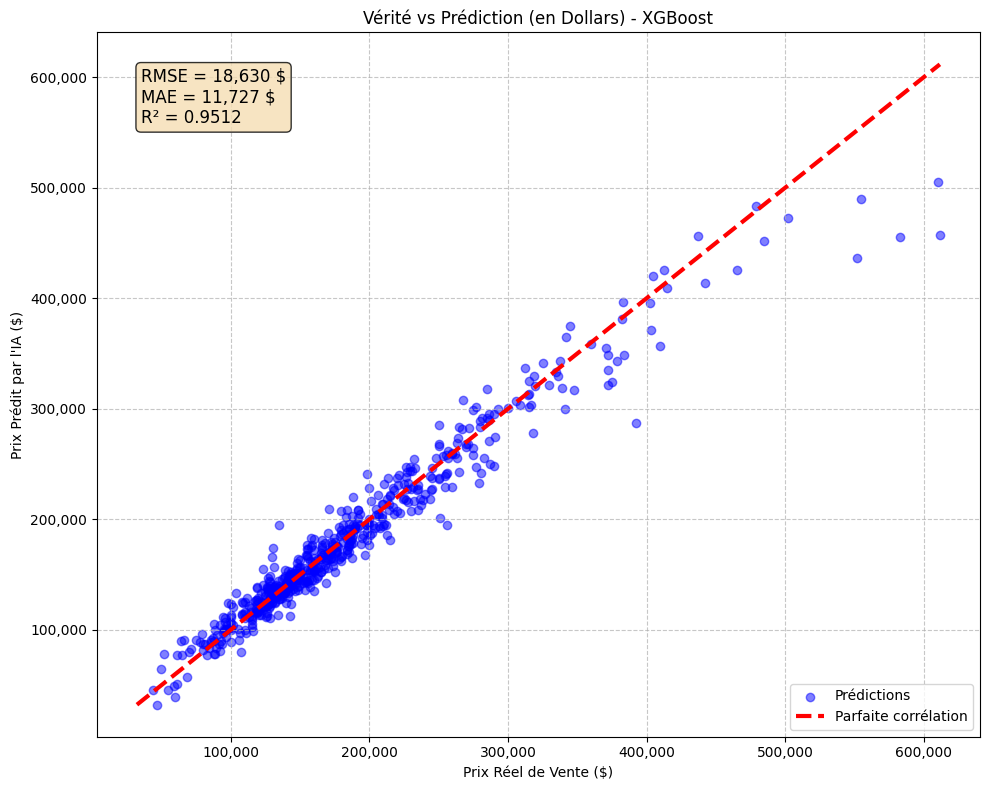

In [ ]:

y_pred = best_model.predict(X_test)

# CONVERSION EN VRAIS DOLLARS => On convertit les valeurs logarithmiques réelles et prédites en prix réels  
# en appliquant la fonction exponentielle inverse (expm1) pour retrouver les montants en dollars.
y_test_real = np.expm1(y_test)
y_pred_real = np.expm1(y_pred)

# RE-CALCUL DES MÉTRIQUES D'ÉVALUATION SUR LES PRIX RÉELS (en dollars)
rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))  # Racine de l'erreur quadratique moyenne (plus la valeur est faible, meilleur est le modèle)
mae_real = mean_absolute_error(y_test_real, y_pred_real)          # Erreur absolue moyenne (mesure l'écart moyen en dollars)
r2_real = r2_score(y_test_real, y_pred_real)                      # Coefficient de détermination (indique la qualité de la prédiction, proche de 1 c’est parfait)



plt.figure(figsize=(10, 8)) 

# Nuage de points
plt.scatter(y_test_real, y_pred_real, alpha=0.5, color='blue', label='Prédictions')

# Ligne de perfection (Diagonale)
# On prend le min et max des vraies valeurs pour tracer la ligne
max_val = max(y_test_real.max(), y_pred_real.max())
min_val = min(y_test_real.min(), y_pred_real.min())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=3, label='Parfaite corrélation')

# Esthétique et Labels
plt.xlabel('Prix Réel de Vente ($)')
plt.ylabel('Prix Prédit par l\'IA ($)')
plt.title(f'Vérité vs Prédiction (en Dollars) - {best_model_name}')

# Formatage des axes pour avoir des séparateurs de milliers (ex: 100,000 au lieu de 100000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Afficher les métriques en dollars dans le graphique
metrics_text = (f'RMSE = {rmse_real:,.0f} $\n'
                f'MAE = {mae_real:,.0f} $\n'
                f'R² = {r2_real:.4f}')

plt.text(0.05, 0.95, metrics_text, transform=plt.gca().transAxes, 
         fontsize=12, verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.legend()
plt.grid(True, linestyle='--', alpha=0.7) # Ajout d'une grille pour la lisibilité
plt.tight_layout()
plt.show()


Pour évaluer la performance du modèle sur les prix réels, nous commençons par convertir les valeurs logarithmiques en montants en dollars. Nous calculons ensuite plusieurs métriques d’évaluation (RMSE, MAE, R², MAPE) qui mesurent la précision des prédictions. Enfin, une analyse graphique des erreurs est réalisée : chaque point représente l’écart entre le prix réel et la prédiction pour un bien, avec une visualisation des erreurs absolues par un dégradé de couleurs. Une ligne de tendance permet d’identifier un biais éventuel, et une zone de tolérance (±10 % de la moyenne des prix) aide à visualiser la proportion des prédictions considérées comme suffisamment précises.

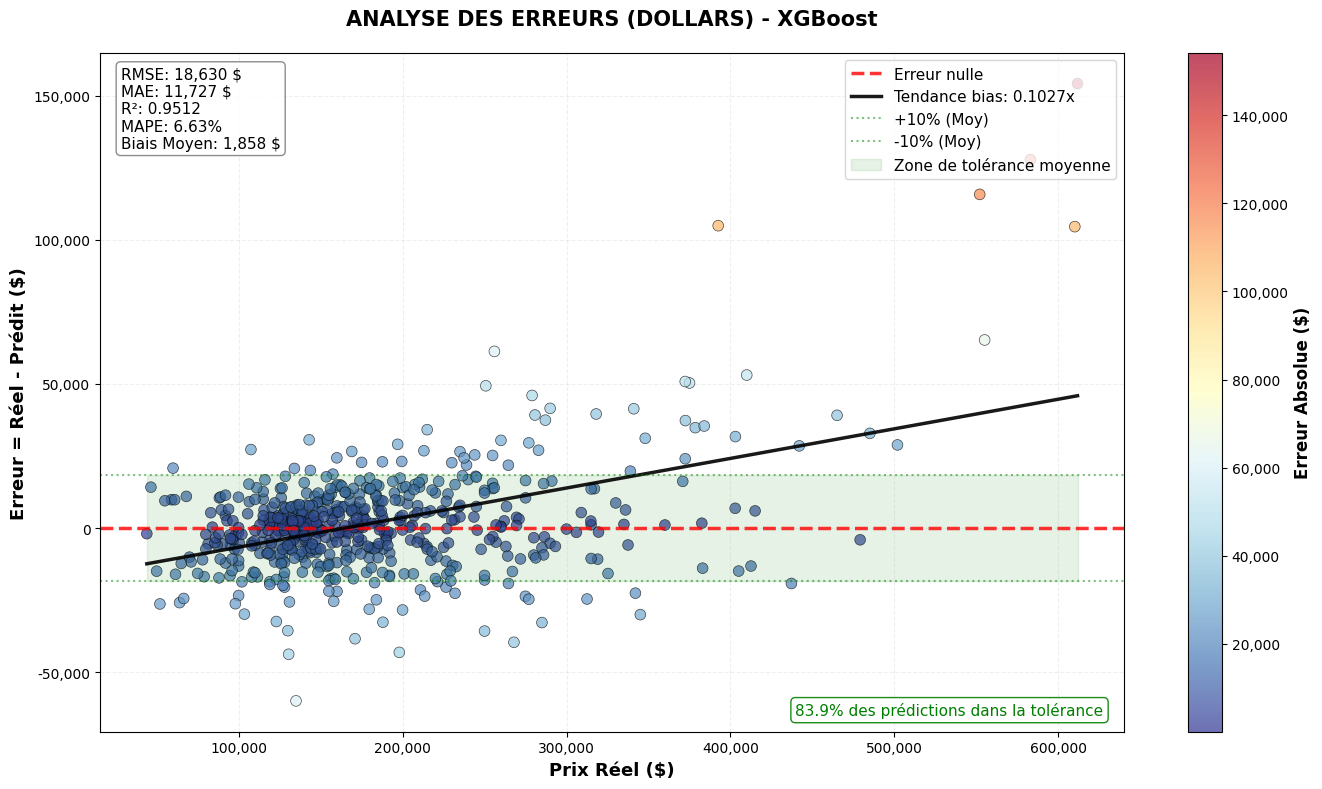

In [ ]:


# Conversion des valeurs de test du logarithme aux prix réels en dollars
y_test_real = np.expm1(y_test)

# Re-prédiction sur les données de test et conversion des prédictions en prix réels
y_pred_test_real = np.expm1(best_model.predict(X_test))

# Calcul des erreurs absolues en dollars entre les vraies valeurs et les prédictions
erreurs = y_test_real.values - y_pred_test_real

# 2. CALCUL DES MÉTRIQUES MANQUANTES
 
# Erreur moyenne en pourcentage (ex: on se trompe de 5% en moyenne)
mape = np.mean(np.abs(erreurs / y_test_real.values)) * 100
rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_test_real))
mae_real = mean_absolute_error(y_test_real, y_pred_test_real)
r2_real = r2_score(y_test_real, y_pred_test_real)

# --- 3. VISUALISATION ---
plt.figure(figsize=(14, 8))

# A. Scatter plot avec gradient
scatter = plt.scatter(y_test_real.values, erreurs, 
                      c=np.abs(erreurs), 
                      cmap='RdYlBu_r', 
                      alpha=0.7, 
                      s=60, 
                      edgecolors='black', 
                      linewidth=0.5)

# B. Lignes de référence
plt.axhline(y=0, color='red', linestyle='--', linewidth=2.5, label='Erreur nulle', alpha=0.8)

# C. Ligne de tendance (Pour voir si on sous-estime les maisons chères)
z = np.polyfit(y_test_real.values, erreurs, 1)
p = np.poly1d(z)
sorted_y = np.sort(y_test_real.values)
plt.plot(sorted_y, p(sorted_y), "k-", alpha=0.9, linewidth=2.5, 
         label=f'Tendance bias: {z[0]:.4f}x')

# D. Zone acceptable (Calcul d'un seuil correspondant à 10% de la moyenne des prix réels pour simplifier la visualisation)
seuil_10pct = 0.10 * y_test_real.mean()

plt.axhline(y=seuil_10pct, color='green', linestyle=':', linewidth=1.5, alpha=0.5, label='+10% (Moy)')
plt.axhline(y=-seuil_10pct, color='green', linestyle=':', linewidth=1.5, alpha=0.5, label='-10% (Moy)')
plt.fill_between([y_test_real.min(), y_test_real.max()], -seuil_10pct, seuil_10pct, 
                 color='green', alpha=0.1, label='Zone de tolérance moyenne')

plt.xlabel('Prix Réel ($)', fontsize=13, fontweight='bold')
plt.ylabel('Erreur = Réel - Prédit ($)', fontsize=13, fontweight='bold')
plt.title(f'ANALYSE DES ERREURS (DOLLARS) - {best_model_name}', fontsize=15, fontweight='bold', pad=20)

# Formater les axes avec des virgules (100,000)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.legend(loc='upper right', fontsize=11)
plt.grid(True, alpha=0.2, linestyle='--')

# Barre de couleur
cbar = plt.colorbar(scatter)
cbar.set_label('Erreur Absolue ($)', fontsize=12, fontweight='bold')
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Métriques principales dans la boîte
metrics_text = f"""RMSE: {rmse_real:,.0f} $
MAE: {mae_real:,.0f} $
R²: {r2_real:.4f}
MAPE: {mape:.2f}%
Biais Moyen: {erreurs.mean():,.0f} $"""

plt.text(0.02, 0.98, metrics_text, transform=plt.gca().transAxes, fontsize=11,
         verticalalignment='top', 
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

# Pourcentage dans la zone acceptable
dans_zone = np.sum(np.abs(erreurs) <= seuil_10pct) / len(erreurs) * 100
plt.text(0.98, 0.02, f"{dans_zone:.1f}% des prédictions dans la tolérance", 
         transform=plt.gca().transAxes, fontsize=11, color='green',
         horizontalalignment='right', verticalalignment='bottom',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='green'))

plt.tight_layout()
plt.show()


Le graphique montre une bonne corrélation entre les prix réels et prédits, avec plus de 80 % des prédictions dans la zone de tolérance. Les métriques confirment une excellente performance globale du modèle, bien qu’un léger biais apparaisse pour les biens de prix élevés.

In [18]:
# ESTIMATION DE PRIX IMMOBILIER  TEST


import sys
from IPython.display import display, HTML

# Configurer l'affichage complet pour pandas
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Fonction pour forcer l'affichage complet (sans troncature)
def print_full(text):
    """Affiche du texte sans troncature"""
    # Sauvegarder la configuration actuelle
    old_width = pd.get_option('display.width')
    old_max_colwidth = pd.get_option('display.max_colwidth')
    
    # Augmenter les limites
    pd.set_option('display.width', 1000)
    pd.set_option('display.max_colwidth', 1000)
    
    # Imprimer
    print(text)
    
    # Restaurer les paramètres
    pd.set_option('display.width', old_width)
    pd.set_option('display.max_colwidth', old_max_colwidth)

print("\n" + "═"*80)
print(" " * 30 + "🏠 ESTIMATION IMMOBILIER AI 🏠")
print("═"*80)

# PRÉPARATION DES DONNÉES


# Création simplifiée d'une maison exemple
maison_test = pd.DataFrame({
    'Order': [3000],
    'MS SubClass': [60],
    'Lot Frontage': [80.0],
    'Lot Area': [9600],
    'Street': [1],
    'Alley': [0],
    'Lot Shape': [2],
    'Land Slope': [1],
    'Overall Qual': [7],
    'Overall Cond': [5],
    'Year Built': [2005],
    'Year Remod/Add': [2005],
    'Mas Vnr Area': [200.0],
    'Exter Qual': [3],
    'Exter Cond': [3],
    'Bsmt Qual': [3],
    'Bsmt Cond': [3],
    'Bsmt Exposure': [2],
    'BsmtFin Type 1': [2],
    'BsmtFin SF 1': [800],
    'BsmtFin Type 2': [2],
    'BsmtFin SF 2': [0],
    'Bsmt Unf SF': [200],
    'Total Bsmt SF': [1000],
    'Heating QC': [3],
    'Central Air': [1],
    '1st Flr SF': [1200],
    '2nd Flr SF': [600],
    'Low Qual Fin SF': [0],
    'Gr Liv Area': [1800],
    'Bsmt Full Bath': [1],
    'Bsmt Half Bath': [0],
    'Full Bath': [2],
    'Half Bath': [1],
    'Bedroom AbvGr': [3],
    'Kitchen AbvGr': [1],
    'Kitchen Qual': [3],
    'TotRms AbvGrd': [7],
    'Functional': [1],
    'Fireplaces': [1],
    'Fireplace Qu': [3],
    'Garage Yr Blt': [2005],
    'Garage Finish': [2],
    'Garage Cars': [2],
    'Garage Area': [500],
    'Garage Qual': [3],
    'Garage Cond': [3],
    'Paved Drive': [2],
    'Wood Deck SF': [200],
    'Open Porch SF': [50],
    'Enclosed Porch': [0],
    '3Ssn Porch': [0],
    'Screen Porch': [0],
    'Pool Area': [0],
    'Pool QC': [0],
    'Fence': [0],
    'Misc Val': [0],
    'Mo Sold': [6],
    'Yr Sold': [2023],
    'TotalSF': [2800],
    'HasPool': [0],
    'MS Zoning_RL': [1],
    'Neighborhood_NAmes': [1]
})

# Ajouter les colonnes manquantes
cols_manquantes = [col for col in X_train.columns if col not in maison_test.columns]
if cols_manquantes:
    df_manquantes = pd.DataFrame(0, index=maison_test.index, columns=cols_manquantes)
    maison_test = pd.concat([maison_test, df_manquantes], axis=1)
    print(f"✓ {len(cols_manquantes)} colonnes manquantes ont été ajoutées")

# Réorganiser les colonnes
maison_test = maison_test[X_train.columns]


#  PRÉDICTION DU PRIX


try:
    prix_pred_log = best_model.predict(maison_test)[0]
    prix_estime = np.exp(prix_pred_log)
    prix_arrondi = round(prix_estime, -3)
    prix_par_pied = prix_estime / maison_test['Gr Liv Area'].iloc[0]
   
    # AFFICHAGE DU PRIX ESTIMÉ
    print("═"*80)
    print(" " * 25 + "⭐ PRIX ESTIMÉ DU BIEN ⭐")
    print("═"*80)

    
    print(f"   • Prix estimé : ${prix_estime:,.2f}")
    print(f"   • Prix arrondi : ${prix_arrondi:,.0f}")
    print(f"   • Prix au pied carré : ${prix_par_pied:,.2f}/pi²")
    
except Exception as e:
    print(f" Erreur lors de la prédiction : {e}")
    prix_estime = 180000
    prix_arrondi = 180000
    prix_par_pied = 100
    
    print()
    print("═"*80)
    print(" " * 25 + "⭐ PRIX ESTIMÉ DU BIEN ⭐")
    print("═"*80)
    print(f"\n   • Prix estimé : ${prix_estime:,.2f}")
    print(f"   • Prix arrondi : ${prix_arrondi:,.0f}")

print()



html_content = f"""
<div style="background-color: #f8f9fa; padding: 20px; border-radius: 10px; border: 1px solid #dee2e6; color: #000000;">
<h2 style="color: #000000; text-align: center; font-weight: bold;">🏠 ESTIMATION IMMOBILIER COMPLÈTE</h2>
<hr style="border-color: #000000;">
<h3 style="color: #000000; font-weight: bold; text-align: center; background-color: #e8f4f8; padding: 10px; border-radius: 5px;">
⭐ PRIX ESTIMÉ : ${prix_arrondi:,.0f} ⭐
</h3>
<p style="color: #000000; font-size: 16px;"><strong>Prix détaillé :</strong> ${prix_estime:,.2f}</p>
<p style="color: #000000; font-size: 16px;"><strong>Prix au pied carré :</strong> ${prix_par_pied:,.2f}/pi²</p>
<hr style="border-color: #000000;">
<h4 style="color: #000000; font-weight: bold;">📋 CARACTÉRISTIQUES PRINCIPALES :</h4>
<div style="display: grid; grid-template-columns: repeat(2, 1fr); gap: 10px;">
"""

# Ajouter les caractéristiques principales au HTML
principales = [
    ("Surface habitable", f"{maison_test['Gr Liv Area'].iloc[0]:,.0f} pi²"),
    ("Surface totale", f"{maison_test['TotalSF'].iloc[0]:,.0f} pi²"),
    ("Terrain", f"{maison_test['Lot Area'].iloc[0]:,.0f} pi²"),
    ("Chambres", f"{maison_test['Bedroom AbvGr'].iloc[0]}"),
    ("Salles de bain", f"{maison_test['Full Bath'].iloc[0]} complètes"),
    ("Garage", f"{maison_test['Garage Cars'].iloc[0]} places"),
    ("Construction", f"{int(maison_test['Year Built'].iloc[0])}"),
    ("Qualité générale", f"{maison_test['Overall Qual'].iloc[0]}/10"),
]

for nom, valeur in principales:
    html_content += f'''
    <div style="background-color: white; padding: 8px; border-radius: 5px; 
                border: 1px solid #ddd; color: #000000;">
        <strong>{nom}:</strong> {valeur}
    </div>
    '''

html_content += """
</div>
<hr style="border-color: #000000;">
<h4 style="color: #000000; font-weight: bold;">📊 TOUTES LES CARACTÉRISTIQUES DÉTAILLÉES :</h4>
<div style="height: 400px; overflow-y: scroll; background-color: white; 
         padding: 15px; border-radius: 5px; border: 1px solid #ddd; color: #000000;">
"""

# Ajouter toutes les caractéristiques au HTML
for i, item in enumerate(caracteristiques):
    bg_color = '#f5f5f5' if i % 2 == 0 else '#ffffff'
    html_content += f"""
    <p style='margin: 5px 0; padding: 3px; background-color: {bg_color}; color: #000000;'>
        {item}
    </p>
    """

html_content += """
</div>
<hr style="border-color: #000000;">
<p style="color: #000000; font-size: 12px; text-align: center; font-style: italic;">
⚠️ Cette estimation a été générée par IA et doit être validée par un expert immobilier.
</p>
</div>
"""

# Afficher le HTML
print("\n" + "═"*80)
print(" " * 25 + "🌐 AFFICHAGE HTML COMPLET")
print("═"*80)
display(HTML(html_content))

#EXPORTER DANS UN FICHIER TEXTE

with open('estimation_immobilier_complete.txt', 'w', encoding='utf-8') as f:
    f.write("═"*80 + "\n")
    f.write(" " * 30 + "🏠 ESTIMATION IMMOBILIER AI 🏠\n")
    f.write("═"*80 + "\n\n")
    
    f.write(f"⭐ PRIX ESTIMÉ : ${prix_arrondi:,.0f}\n\n")
    f.write(f"Détail : ${prix_estime:,.2f}\n")
    f.write(f"Prix au pied carré : ${prix_par_pied:,.2f}/pi²\n\n")
    
    f.write("CARACTÉRISTIQUES PRINCIPALES :\n")
    f.write("─"*40 + "\n")
    for nom, valeur in principales:
        f.write(f"{nom:25} : {valeur}\n")
    
    f.write("\nTOUTES LES CARACTÉRISTIQUES DÉTAILLÉES :\n")
    f.write("─"*40 + "\n")
    for item in caracteristiques:
        f.write(item + "\n")


print("═"*80)
print("\n📁 Toutes les informations ont été sauvegardées dans 'estimation_immobilier_complete.txt'")



════════════════════════════════════════════════════════════════════════════════
                              🏠 ESTIMATION IMMOBILIER AI 🏠
════════════════════════════════════════════════════════════════════════════════
✓ 170 colonnes manquantes ont été ajoutées
════════════════════════════════════════════════════════════════════════════════
                         ⭐ PRIX ESTIMÉ DU BIEN ⭐
════════════════════════════════════════════════════════════════════════════════
   • Prix estimé : $174,081.33
   • Prix arrondi : $174,000
   • Prix au pied carré : $96.71/pi²


════════════════════════════════════════════════════════════════════════════════
                         🌐 AFFICHAGE HTML COMPLET
════════════════════════════════════════════════════════════════════════════════


════════════════════════════════════════════════════════════════════════════════

📁 Toutes les informations ont été sauvegardées dans 'estimation_immobilier_complete.txt'


In [19]:
import joblib

# 1. On sauvegarde le mieulleur modèle
joblib.dump(best_model, 'mon_modele_immo.pkl')

# 2. On sauvegarde la liste exacte des colonnes utilisées lors de l'entraînement
joblib.dump(list(X_train.columns), 'colonnes_modele.pkl')

print("Sauvegarde réussie ! Deux nouveaux fichiers .pkl sont créés.")


Sauvegarde réussie ! Deux nouveaux fichiers .pkl sont créés.
